# Задача 5. Более умный источник

Для события с энергией $E$ число сцинтилляционных фотонов теперь
флуктуирует:

$$N_\gamma\sim\operatorname{Poisson}(EY).$$

Метод `Source.photon_batches` реализован как генератор. Он один
раз разыгрывает $N_\gamma$, а затем лениво выдаёт массивы не
более чем по 100 изотропных единичных направлений. Поэтому для
большого события не требуется заранее хранить все фотоны.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.model import Source

source = Source(Y=10_000.0, position=np.zeros(3))
energy = 0.2
rng = np.random.default_rng(5201)
counts = np.array([
    source.sample_photon_count(energy, rng) for _ in range(20_000)
])
expectation = energy * source.Y

print(f"Теоретические E[N] = Var(N) = {expectation:.1f}")
print(f"Выборочное среднее:   {counts.mean():.2f}")
print(f"Выборочная дисперсия: {counts.var(ddof=1):.2f}")

Теоретические E[N] = Var(N) = 2000.0
Выборочное среднее:   2000.16
Выборочная дисперсия: 2043.17


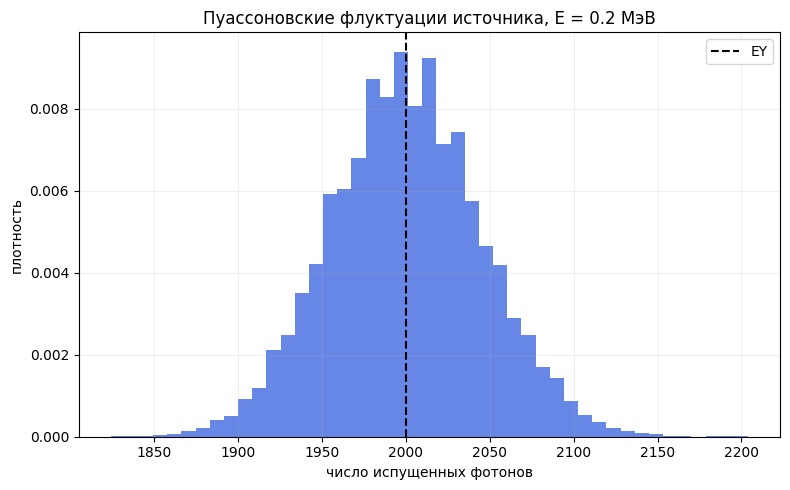

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(counts, bins=45, density=True, color="royalblue", alpha=0.8)
ax.axvline(expectation, color="black", linestyle="--", label="EY")
ax.set(xlabel="число испущенных фотонов", ylabel="плотность",
       title="Пуассоновские флуктуации источника, E = 0.2 МэВ")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig("figures/task5_poisson_source.png", dpi=180, bbox_inches="tight")
plt.show()

In [3]:
batch_rng = np.random.default_rng(5202)
batches = list(source.photon_batches(1.0, batch_rng, batch_size=100))
sizes = np.array([len(batch) for batch in batches])
all_directions = np.vstack(batches) if batches else np.empty((0, 3))

assert np.all(sizes[:-1] == 100)
assert sizes[-1] <= 100
assert np.allclose(np.linalg.norm(all_directions, axis=1), 1.0)

print("Число фотонов в событии:", len(all_directions))
print("Число пакетов:", len(batches))
print("Размеры первых пяти пакетов:", sizes[:5])
print("Размер последнего пакета:", sizes[-1])
print("Среднее направление:", all_directions.mean(axis=0))

Число фотонов в событии: 9961
Число пакетов: 100
Размеры первых пяти пакетов: [100 100 100 100 100]
Размер последнего пакета: 61
Среднее направление: [-0.0044249   0.00372257 -0.0135864 ]


**Вывод.** Среднее и дисперсия числа фотонов согласуются с
распределением Пуассона. Генератор сохраняет изотропность и
ограничивает размер каждого возвращаемого массива ста фотонами.